In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform

# sns.set_context("talk")


VIDEO_FOLDER = "/home/bw/Projects/c02-fish/Videos"
pd.set_option('display.max_columns', None)
DATA_FOLDER = "tracking_output/"

In [2]:
def compute_radius(x, y, x_center, y_center):
    """Computes the distance between (x, y) and (x_center, y_center)."""
    return ((x - x_center) ** 2 + (y - y_center) ** 2) ** 0.5

assert compute_radius(0, 0, 0, 0) == 0
assert compute_radius(10, 100, 10, 100) == 0
assert compute_radius(100, 0, 0, 0) == 100
assert compute_radius(0, 100, 0, 0) == 100
assert compute_radius(1, 1, 0, 0) == 2 ** 0.5
assert compute_radius(3, 3, 2, 2) == 2 ** 0.5

In [3]:
# Loads the data.
# 
# This reads the csvs individually, adds identifying columns, and then
# at the end concatenates them all into one table and deletes the originals to save memory.
#
# Arguably this is a little fragile, but this way of doing it
# is at least explicit and lets us mark the columns. So no need to get fancy here.

dfs = []
for river in ["Green", "Skagit"]:
    for pH in [1, 2, 3]:
        for trial in range(1, 11):
            # DATA_FOLDER = VIDEO_FOLDER + f"/River-{river}/pH-{pH}/Trial-{trial}/data/"
            for individual in range(0, 6):
                try:
                    indiv = pd.read_csv(DATA_FOLDER + f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.csv")
                    indiv["River"] = river
                    indiv["pH"] = pH
                    indiv["Trial"] = trial
                    indiv["Individual"] = individual
                    dfs.append(indiv)
                except Exception as e:
                    # Pretty noisy, but this lives on as a loud TODO to get these missing videos tracked.
                    print("skipping", f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.")
                    print(e)

df = pd.concat(dfs, ignore_index=True)
del(dfs)

In [4]:
# Radius correction
PH_TO_X_Y_RADIUS = {
    #   x center, y center, radius
    1: (3840/2 + 75, 2160/2, 1284),
    2: (3840/2 + 144, 2160/2, 1184),
    3: (3840/2 + 30, 2160/2 + 20, 1284),
}

# We don't actually want to save these columns to the dataframe, they're unnecessarily big.
# But doing it like this is in theory faster.
df["center x"] = df.apply(lambda r: PH_TO_X_Y_RADIUS[r["pH"]][0], axis=1)
df["center y"] = df.apply(lambda r: PH_TO_X_Y_RADIUS[r["pH"]][1], axis=1)
df["radius length"] = df.apply(lambda r: PH_TO_X_Y_RADIUS[r["pH"]][2], axis=1)

df["radius"] = compute_radius(
    df["X (cm)"],
    df["Y (cm)"],
    df["center x"],
    df["center y"],
) / df["radius length"]

df["X"] = (df["X (cm)"] - df["center x"])/df["radius length"]
df["Y"] = (df["Y (cm)"] - df["center y"])/df["radius length"]

In [5]:
# Rescale kinematics by radius length
df["speed"] = df["SPEED#wcentroid (cm/s)"] / df["radius length"]
df["acceleration"] = df["ACCELERATION#wcentroid (cm/s2)"]

In [6]:
# Throws out data points with infinite x or y (missing locations)
df = df[~(np.isinf(df["X (cm)"]) | np.isinf(df["Y (cm)"]))]

# Throws out anomolous points with radius > a cutoff.
df = df[df["radius"] <= 1.0]

# This reads the event times (skin extraction & visual disturbance) and then merges these columns in.
# It's more like an SQL join, but pandas calls it `merge`.
event_times = pd.read_csv("event_times.csv")
df = df.merge(event_times, on=["River", "pH", "Trial"])


def to_seconds(s):
    """Converts a string like `25:15` to a number of seconds."""
    m, s = s.split(":")
    return int(m) * 60 + int(s)

# Tests for to_seconds().
assert to_seconds("25:15") == 25 * 60 + 15
assert to_seconds("1:15") == 75

# Go through and convert these strings to seconds.
df["skin_extract_injection_seconds"] = df["Skin extract injection (Video run time)"].apply(to_seconds)
df["visual_disturbance_seconds"] = df["Visual disturbance (Video run time)"].apply(to_seconds)

# Adds columns of time _relative to these events_.
df["skin_extract_injection_time"] = df["time"] - df["skin_extract_injection_seconds"]
df["visual_disturbance_time"] = df["time"] - df["visual_disturbance_seconds"]


# df["radius"] = ((df["Y (cm)"] - CENTER_Y) ** 2 + (df["X (cm)"] - CENTER_X) ** 2) ** 0.5

In [11]:
# Add 99th percentile here.

# For each trial (2 rivers x 10 trials = 20 trials)
# For each minute, there are 6 fish swimming around, and trex records 
# a speed & acceleration measurement for each fish for each frame.
# We take all these measurements over the minute and find the 99th percentile.

QUANTILES = [0.5, 0.9, 0.99]
COLUMNS = ["speed", "acceleration"]
COLUMN_NAMES = ["River", "pH", "Trial"]
for column in COLUMNS:
    for quantile in QUANTILES:
        COLUMN_NAMES.append(column + str(quantile))

data = []

# Adds mean neighbor distances.
for _name, group_df in df.groupby(["River", "pH", "Trial"]):
    river, pH, trial = _name
    

    # for time in [m * 60.0 for m in range(0, 33)]:
    row = [river, pH, trial]
        # minute_slice = group_df[(group_df["time"] >= time) & (group_df["time"] < time + 60)][COLUMNS]

    for column in COLUMNS:
        for quantile in QUANTILES:
            row.append(group_df[column].quantile(quantile))

        

    data.append(row)



by_trial = pd.DataFrame(data, columns = COLUMN_NAMES)
# df = df.merge(by_trial_minute, on=["River", "pH", "Trial", "time"])
# del(by_trial_minute) # These dataframes are big and this is running on my macbook air. So let's clean up things we're not using.



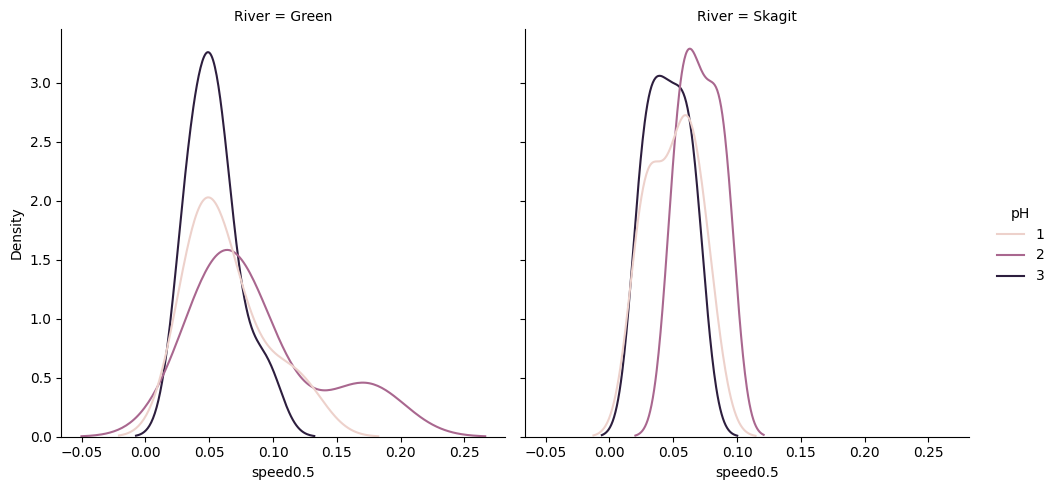

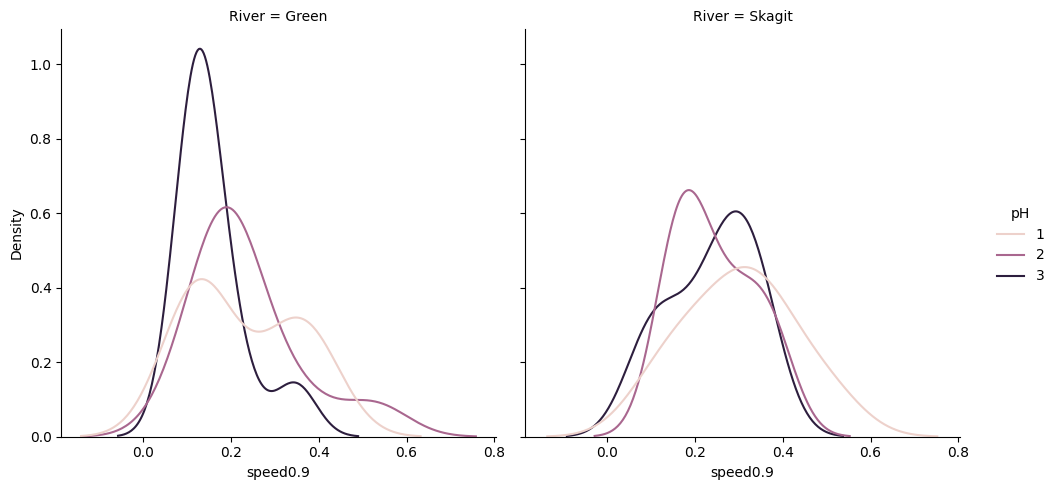

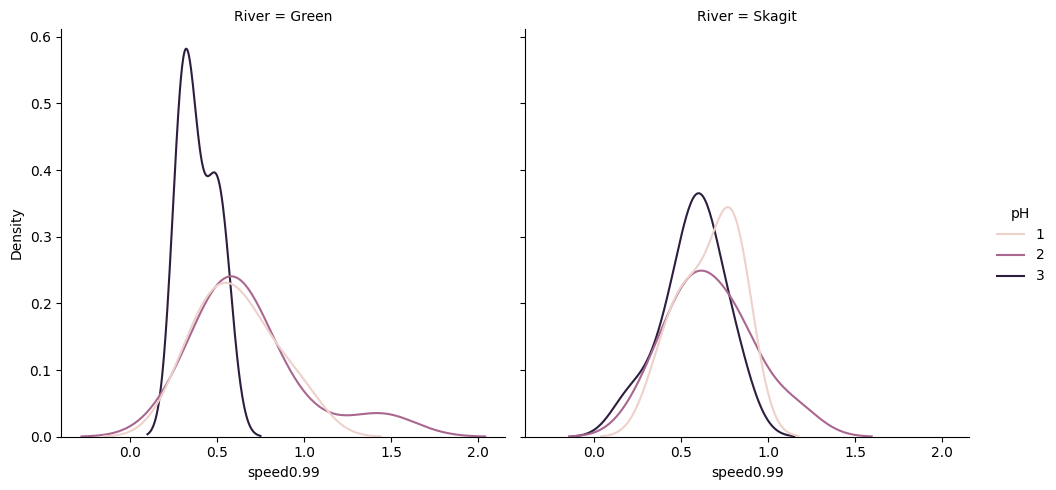

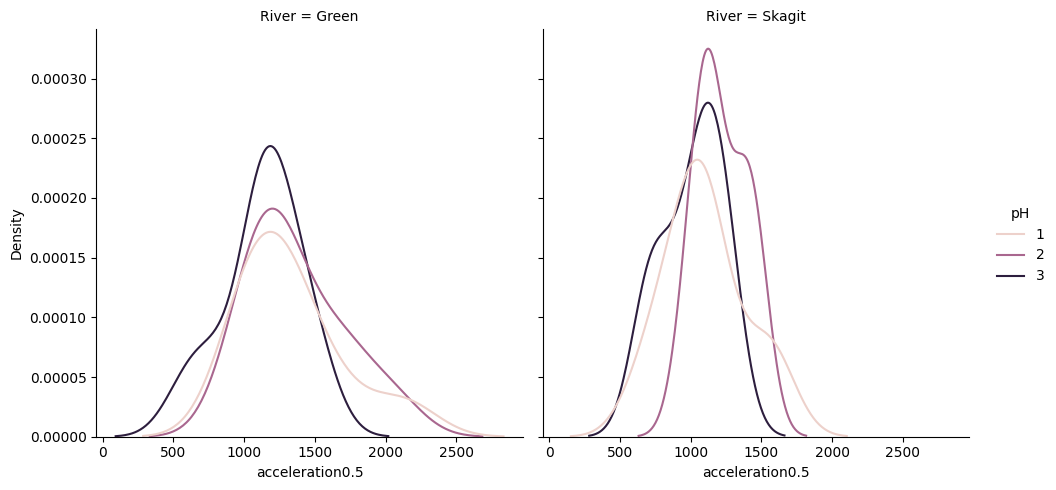

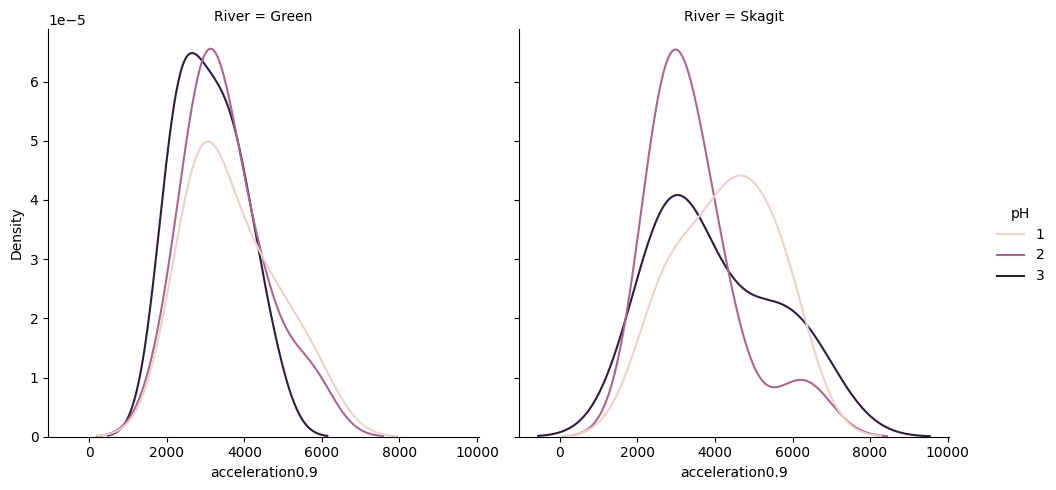

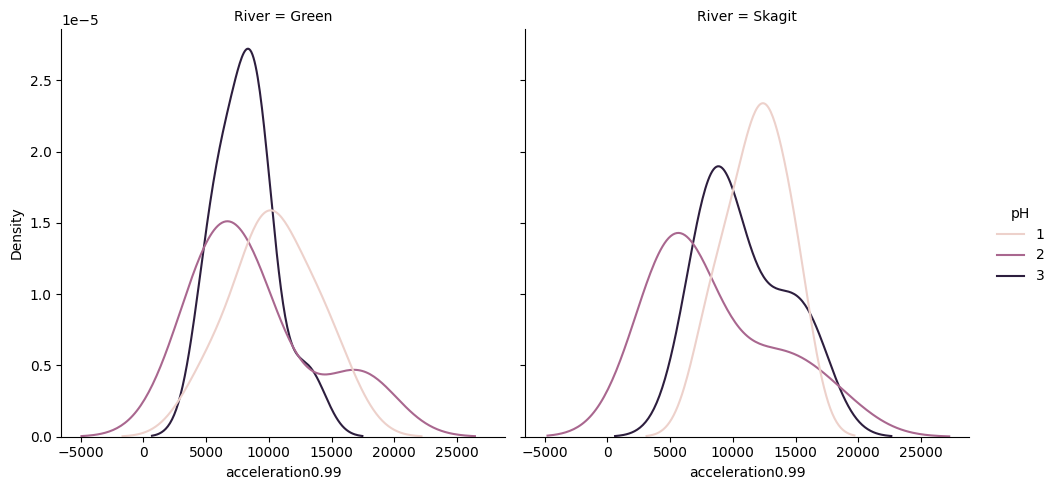

In [24]:
VARIABLES = [
    "speed0.5",
    "speed0.9",
    "speed0.99",
    "acceleration0.5",
    "acceleration0.9",
    "acceleration0.99",
]

for var in VARIABLES:
    sns.displot(data=by_trial, x=var, hue="pH", col="River", kind="kde")

In [8]:
VARIABLES = [
    "speed0.5",
    "speed0.9",
    "speed0.99",
    "acceleration0.5",
    "acceleration0.9",
    "acceleration0.99",
]

# First 10 minutes
first_10 = df[
    (df["time"] > 60) &
    (df["time"] < 60 * 10)]

# 5 minutes before and after skin extract injection.
SKIN_EXTRACT_BEFORE = a, b = (-60 * 1, 0)
SKIN_EXTRACT_AFTER = c, d = (60 * 4, 60 * 5)
skin_extract_before = df[
    ((df["skin_extract_injection_time"] >= a) & (df["skin_extract_injection_time"] <= b))]
skin_extract_after = df[
     ((df["skin_extract_injection_time"] >= c) & (df["skin_extract_injection_time"] <= d))]

# visual disturbance.
VISUAL_DISTURBANCE_BEFORE = a, b = (-60 * 1, 0)
VISUAL_DISTURBANCE_AFTER_SHORT = c, d = (0, 2)
VISUAL_DISTURBANCE_AFTER_LONG = e, f = (2, 30)

visual_disturbance_before = df[
    (df["visual_disturbance_time"] >= a) & (df["visual_disturbance_time"] <= b)]
visual_disturbance_after_short = df[
     ((df["visual_disturbance_time"] >= c) & (df["visual_disturbance_time"] <= d))]
visual_disturbance_after_long = df[
     ((df["visual_disturbance_time"] >= e) & (df["visual_disturbance_time"] <= f))]


/Users/brendan/Library/Python/3.9/lib/python/site-packages/seaborn/axisgrid.py:453: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=figsize)


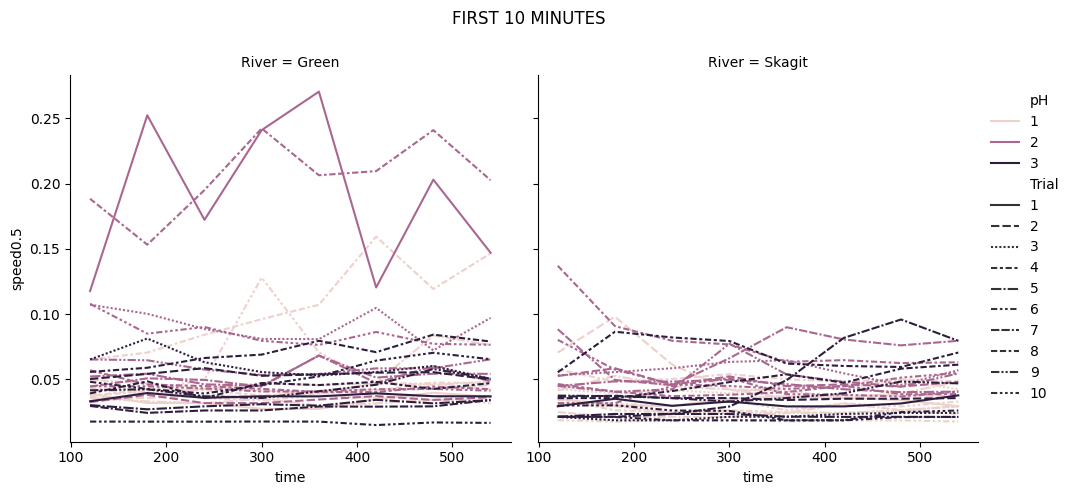

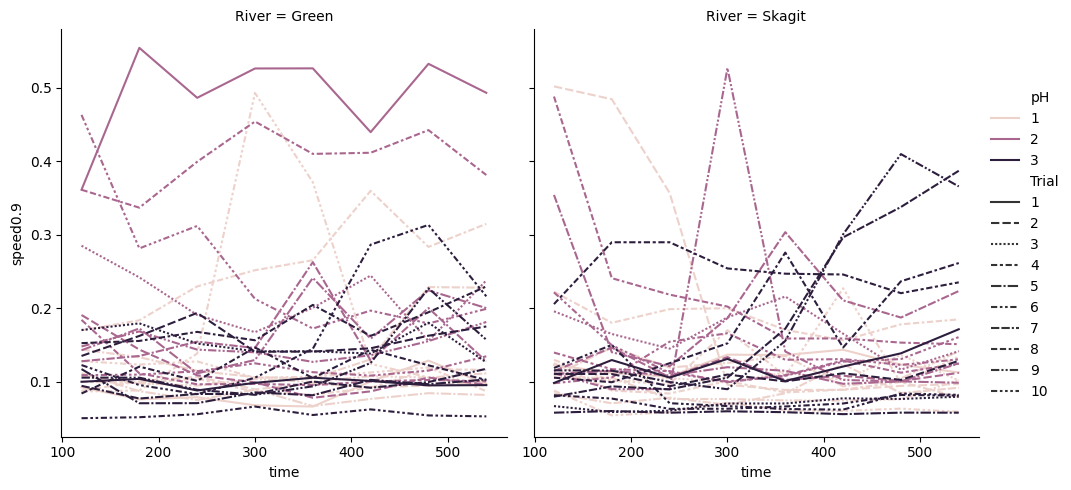

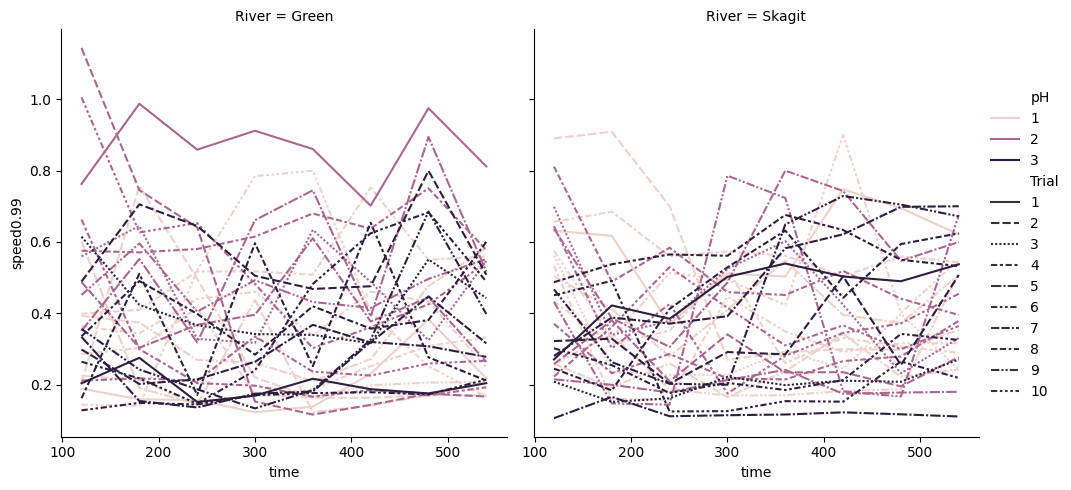

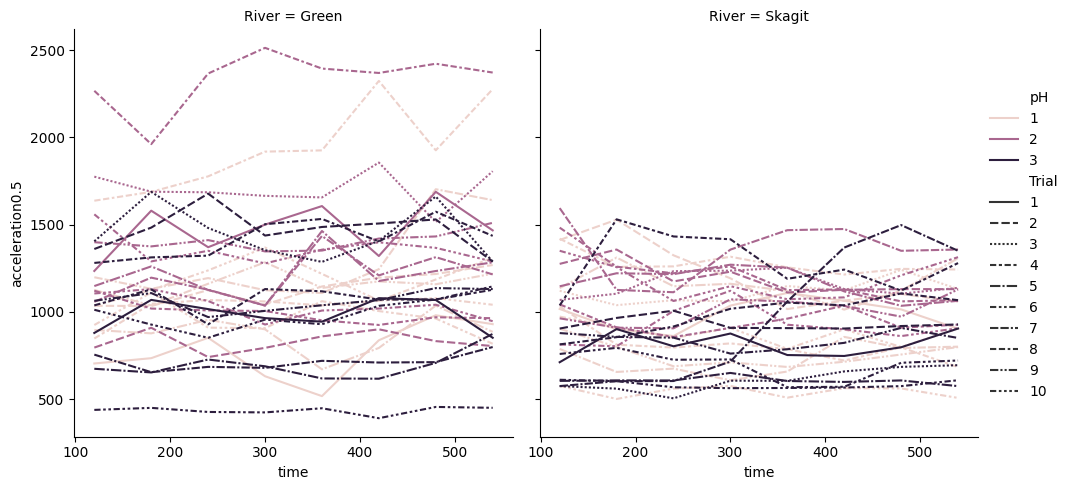

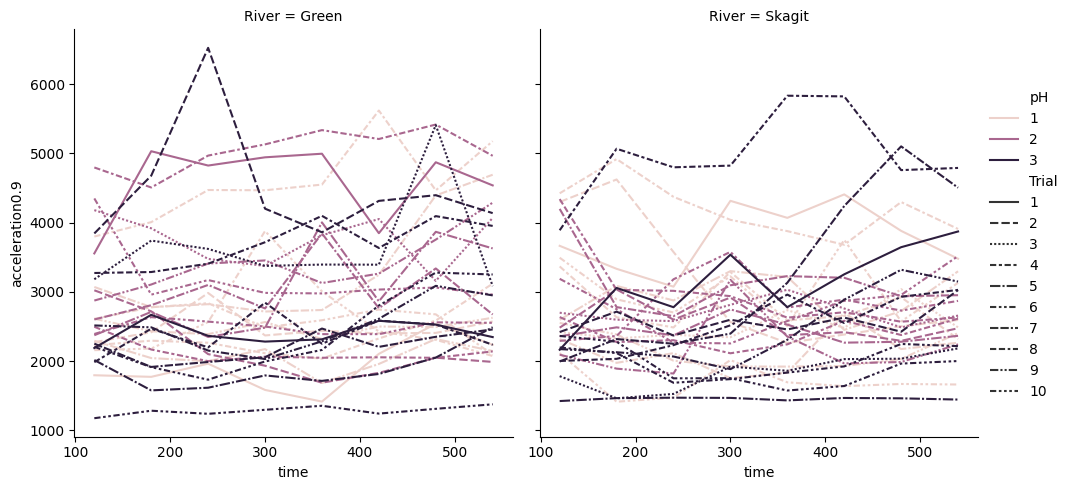

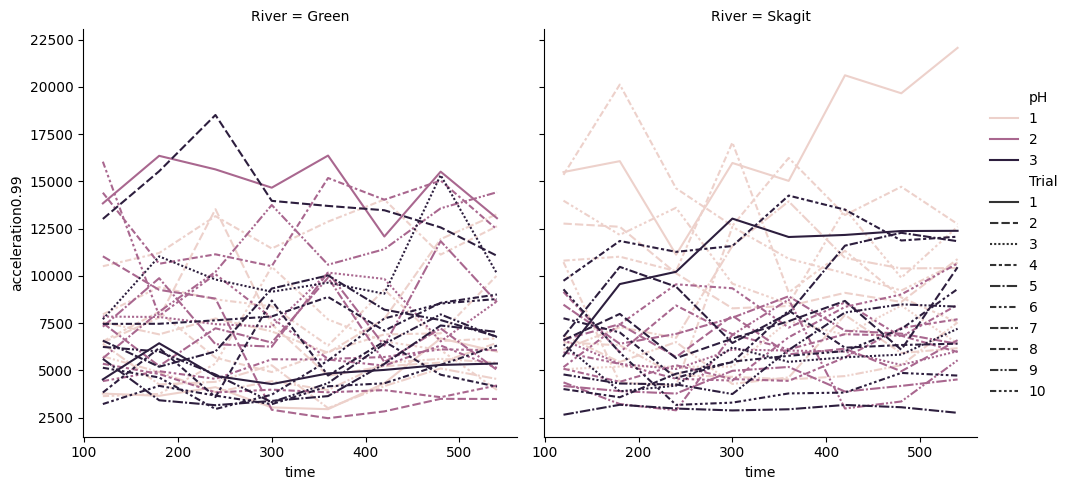

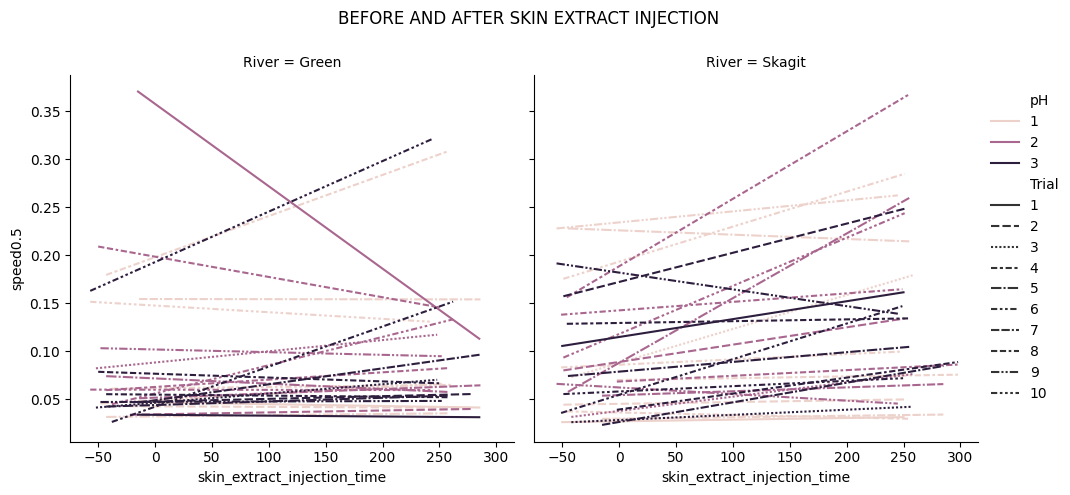

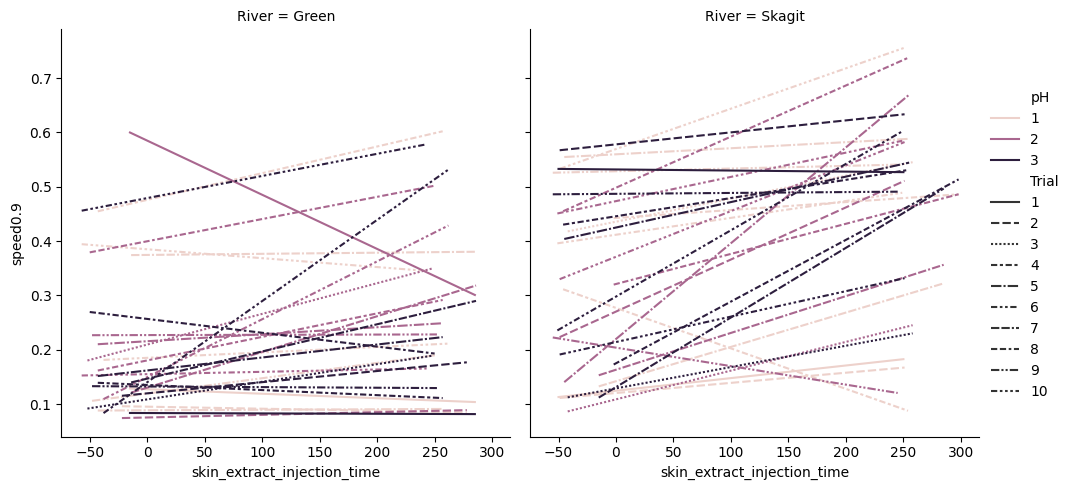

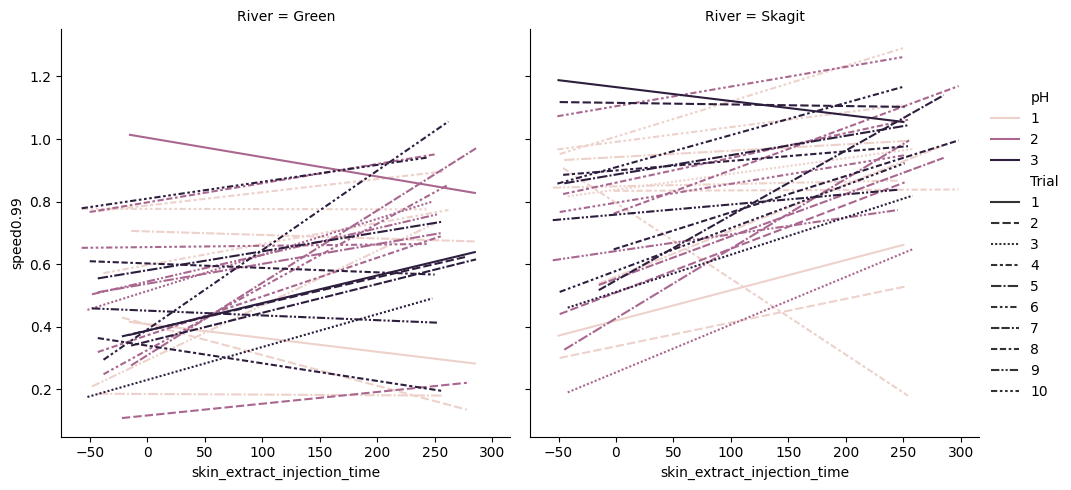

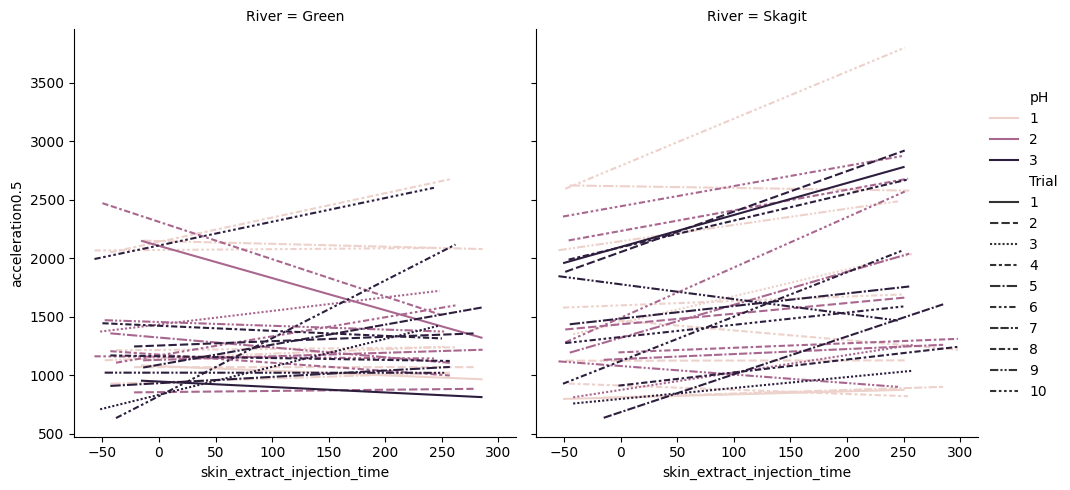

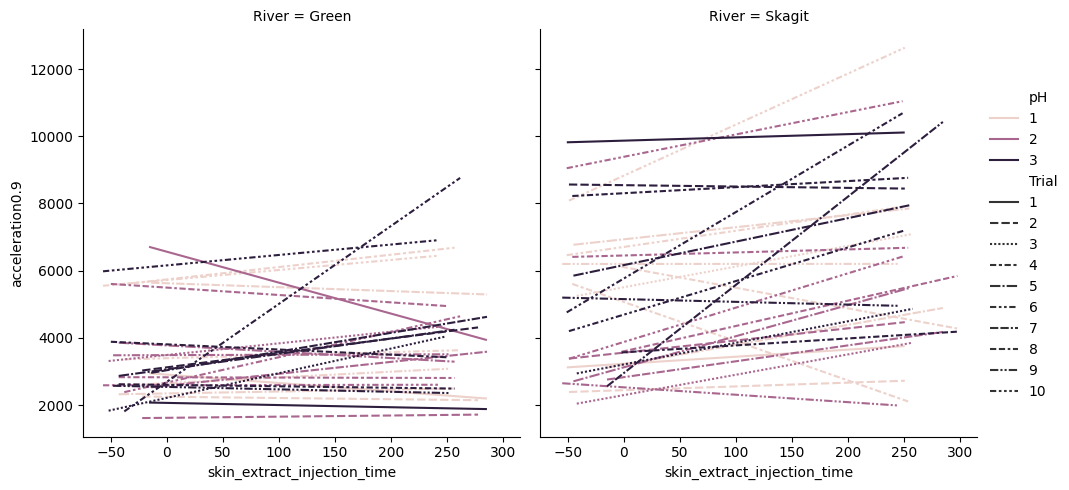

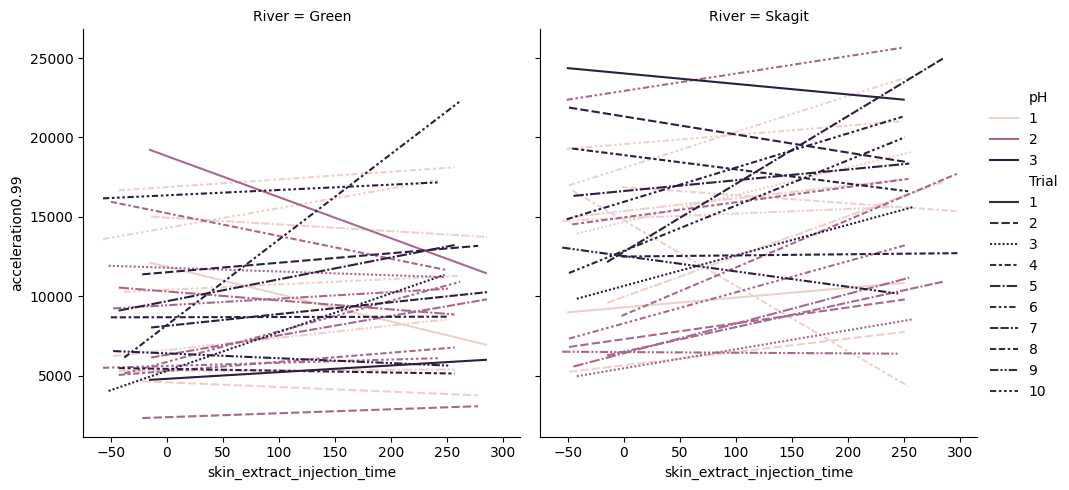

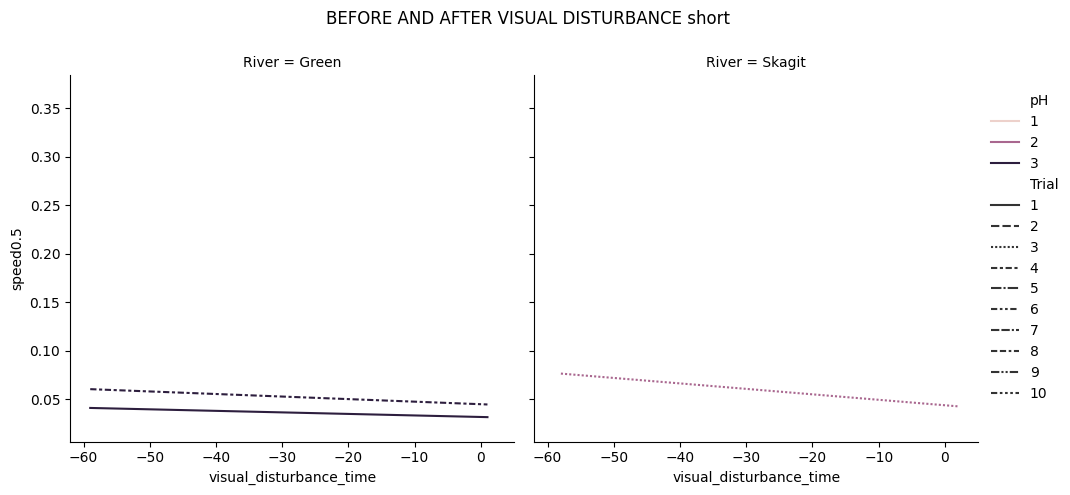

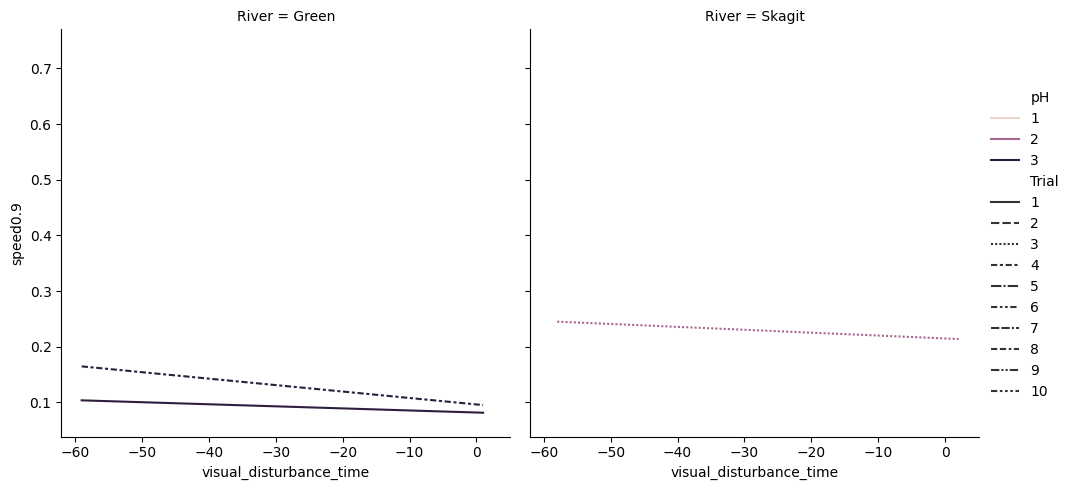

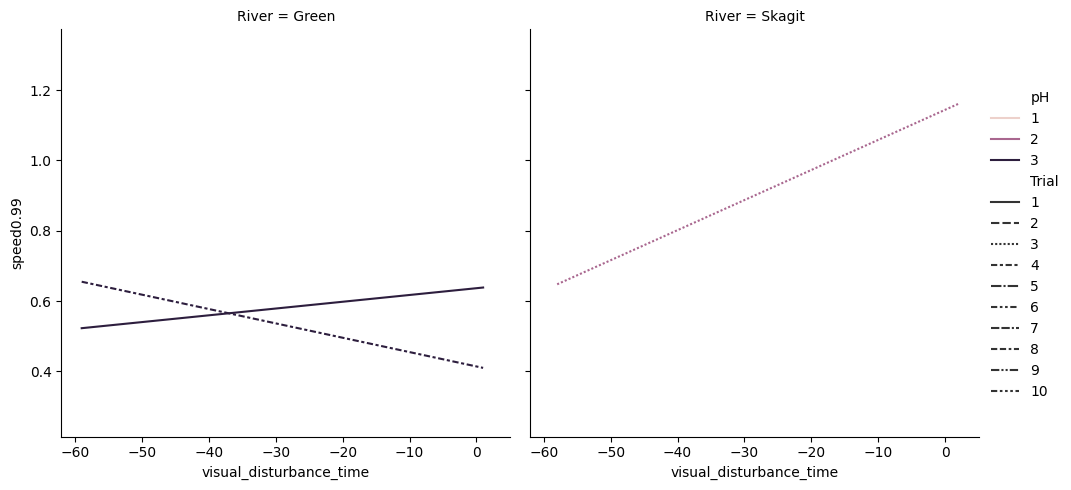

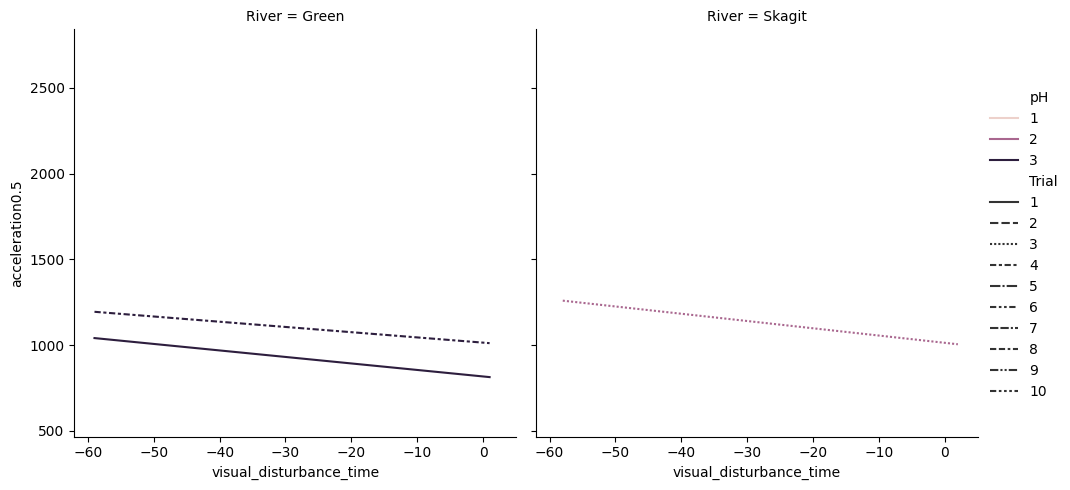

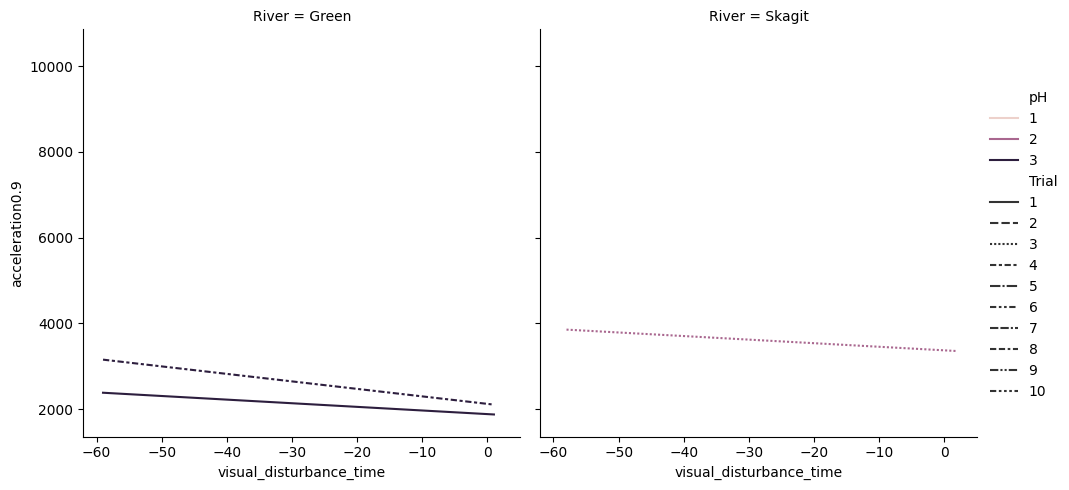

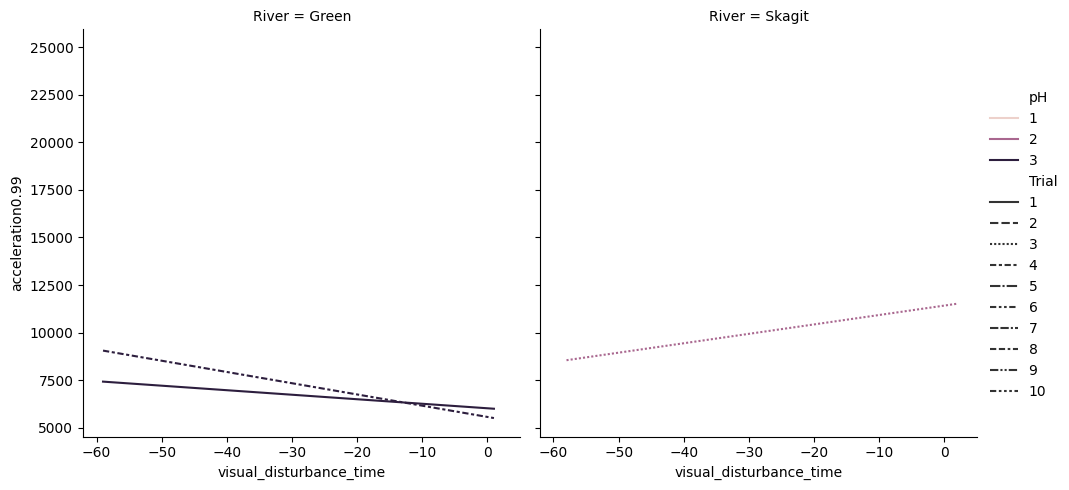

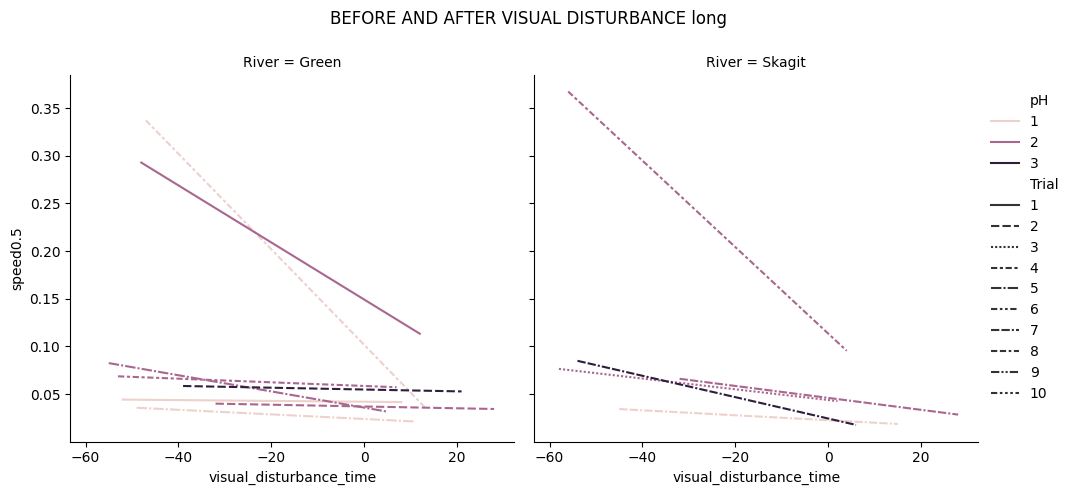

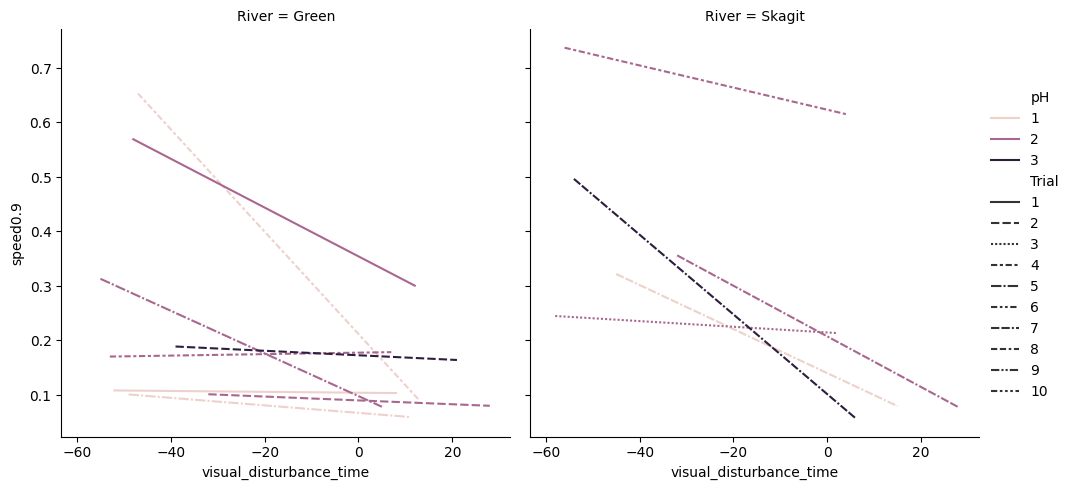

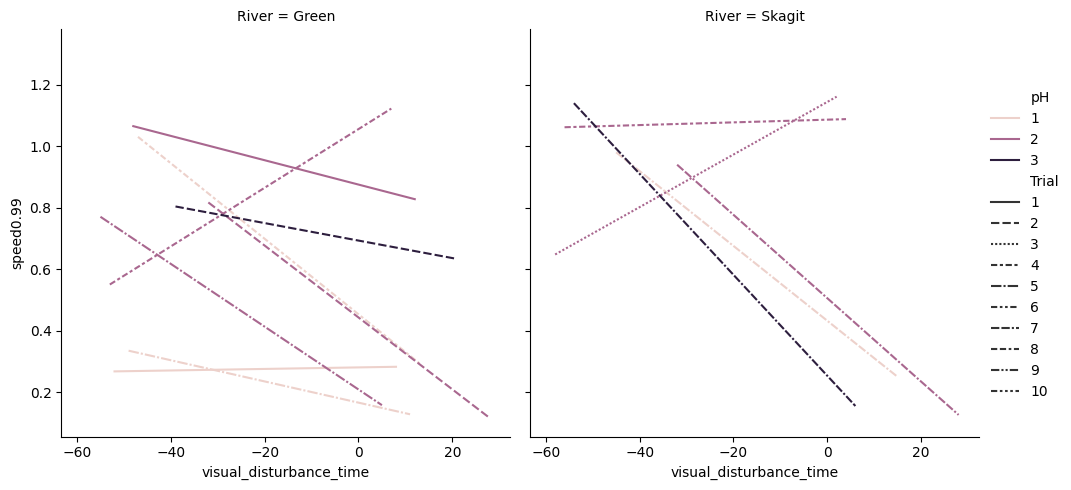

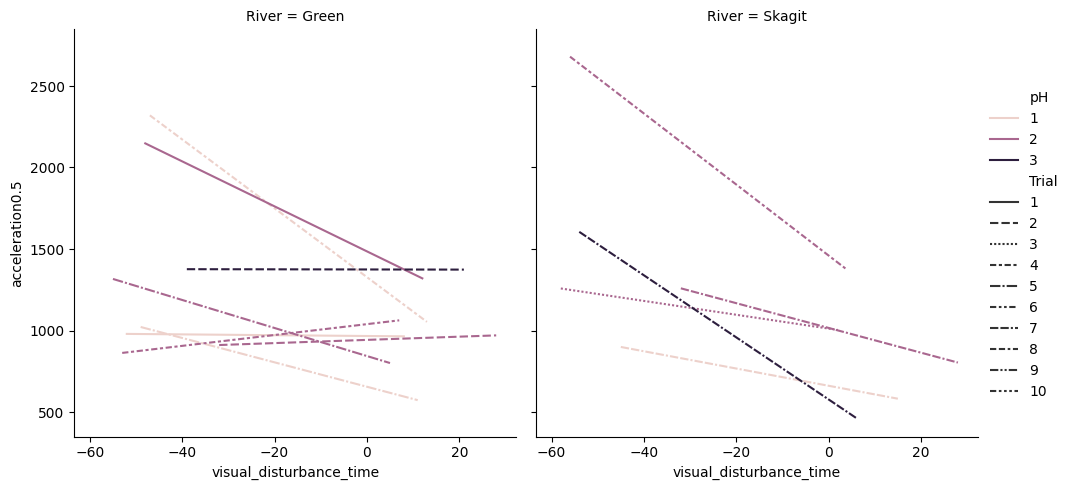

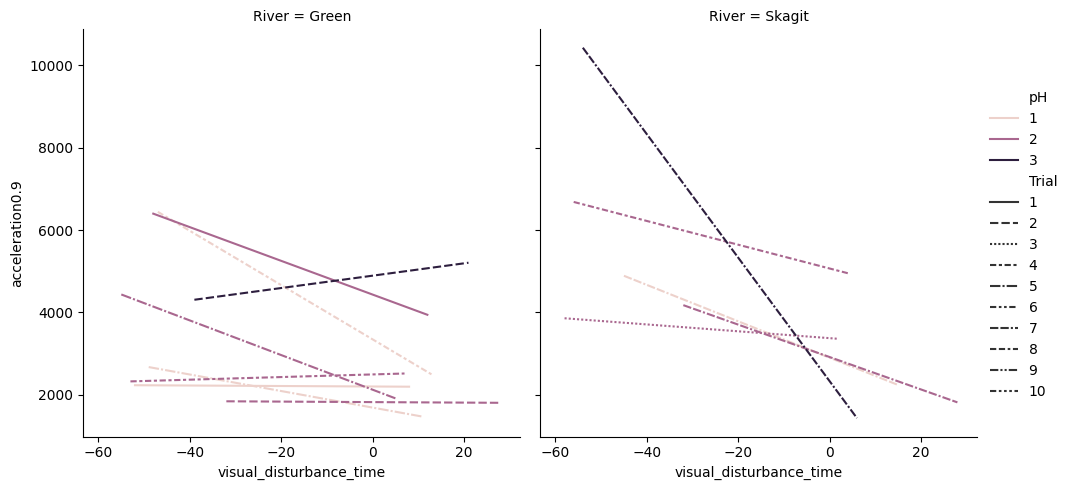

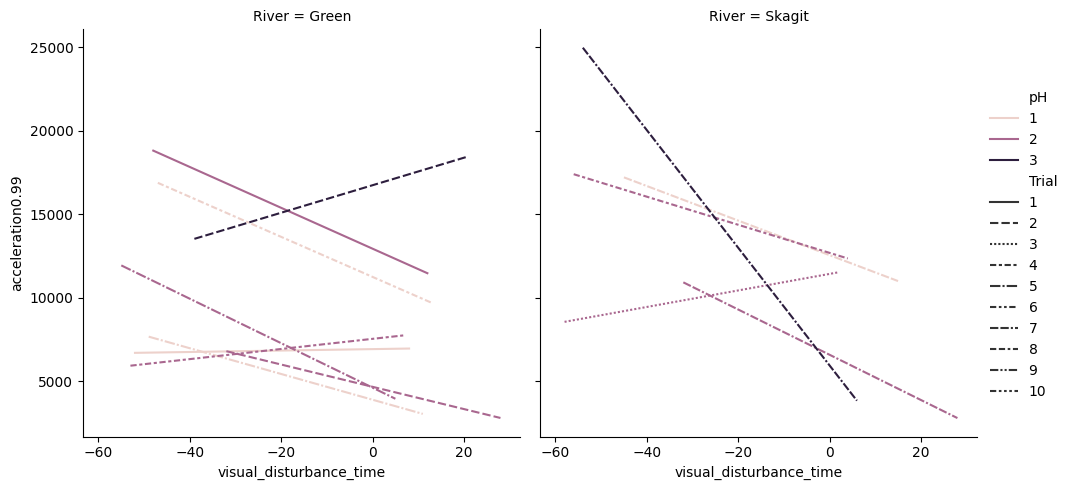

In [9]:
for _df, title, time_var in [
    (first_10, "FIRST 10 MINUTES", "time"),
    (pd.concat([skin_extract_before, skin_extract_after]),
         "BEFORE AND AFTER SKIN EXTRACT INJECTION",  "skin_extract_injection_time"),
    (pd.concat([visual_disturbance_before, visual_disturbance_after_short]),
         "BEFORE AND AFTER VISUAL DISTURBANCE short", "visual_disturbance_time"),
    (pd.concat([visual_disturbance_before, visual_disturbance_after_long]),
     "BEFORE AND AFTER VISUAL DISTURBANCE long", "visual_disturbance_time"),
]:


    for i, var in enumerate(VARIABLES):
        p = sns.relplot(data=_df, x=time_var, y=var, kind="line", col="River", hue="pH", style="Trial", errorbar=None)
        if i == 0:
            p.fig.suptitle(title) # can still add, e.g., fontsize=16
            p.fig.subplots_adjust(top=0.85)
